# Искусственный интеллект — занятие 5
### Нейронные сети: полносвязная сеть, MLP и градиентный спуск

**Логика занятия:** сколько параметров у нейронной сети и как выбирать размеры слоёв → первый классификатор `MLPClassifier` на датасете `res_oval.dat` → задание на перебор размеров скрытых слоёв → ручной градиентный спуск для одной и двух переменных → обратное распространение ошибки → тот же спуск в PyTorch через `requires_grad` и `backward()`.


## 1. Полносвязная нейронная сеть и её параметры

Простейшая архитектура нейронной сети — **полносвязная сеть** (fully connected): входные данные подаются на слой нейронов, и каждый нейрон умножает каждый вход на свой коэффициент, складывает произведения и добавляет смещение:

$$z = \sum_{i=1}^{n} w_i x_i + b$$

То есть на один нейрон нужно $n + 1$ свободных параметров: $n$ весов и одно смещение. Слой таких нейронов называется **скрытым**, а сеть из нескольких слоёв — **многослойным перцептроном (MLP)**.

| Слой | Входов | Нейронов | Параметров |
|---|---|---|---|
| 1 | 4 | 3 | $(4+1)\cdot 3 = 15$ |
| 2 | 3 | 3 | $(3+1)\cdot 3 = 12$ |
| 3 | 3 | 1 | $3+1 = 4$ |
| **Всего** | | | **31** |

Если найти эти 31 коэффициент, сеть начнёт решать задачу. Отсюда главный вопрос: сколько нейронов ставить в скрытые слои. Однозначного ответа нет, это **гиперпараметры**, но есть два ориентира:

- **теорема Колмогорова–Арнольда**: для $n$-мерного входа на первом слое нужно порядка $n^2$ нейронов, на втором — $2n+1$ (для двумерного датасета — 4 и 5). Про функцию активации теорема молчит, а в `MLPClassifier` активация прямоугольная, «ступеньками»;
- **число параметров должно быть порядка числа объектов или меньше**. В датасете порядка 10 тысяч строк — это 10 тысяч «уравнений». Если неизвестных больше, система недоопределена: решений много, и обучение «разваливается» на произвол.

Границы, которые из этого следуют: в первом слое (2 входа) на нейрон нужно 3 параметра, поэтому больше ~3000 нейронов не поставить — а тогда на второй слой остаётся всего ~3 нейрона. Разумный диапазон — около сотни нейронов на слой: сеть $100 \to 100$ имеет $300 + 10\,100 + 101 \approx 10\,500$ параметров. Размеры подбирают перебором, не выходя за эти пределы.

**Дистилляция** — способ затем облегчить уже обученную сеть: коэффициенты, малые по модулю, приравнивают к нулю и соответствующие связи удаляют. Вычислений становится меньше, ответ — быстрее, но точность слегка падает. В `MLPClassifier` этого не сделать, а в TensorFlow/PyTorch — можно.


## 2. Установка библиотек и импорты

Ставим весь стек курса: базовый анализ данных (`numpy`, `pandas`, `scipy`, `matplotlib`, `seaborn`, `tqdm`), классическое машинное обучение (`scikit-learn`, `xgboost`, `lightgbm`, `catboost`), глубокое обучение (`torch`, `torchvision`, `torchaudio`, `tensorflow`, `keras`, `transformers`, `datasets`) и утилиты для Jupyter.

Дальше подключаем то, что нужно сегодня: `numpy`, `matplotlib.pyplot`, `MLPClassifier` из `sklearn.neural_network` и `torch`.


In [1]:
import sys
!{sys.executable} -m pip install torch
import sys

# 1. Базовый стек: Анализ данных, математика и визуализация
!{sys.executable} -m pip install numpy pandas scipy matplotlib seaborn tqdm

# 2. Классическое машинное обучение и инструменты
!{sys.executable} -m pip install scikit-learn xgboost lightgbm catboost

# 3. Глубокое обучение (Deep Learning) и работа с ИИ
!{sys.executable} -m pip install torch torchvision torchaudio
!{sys.executable} -m pip install tensorflow keras
!{sys.executable} -m pip install transformers datasets

# 4. Вспомогательные утилиты для работы в Jupyter
!{sys.executable} -m pip install ipywidgets openpyxl


  Using cached torch-2.14.1-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (37 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached cuda_toolkit-13.0.3.0-py2.py3-none-any.whl.metadata (17 kB)
  Using cached nvidia_cudnn_cu13-9.24.0.43-py3-none-manylinux_2_27_x86_64.whl.metadata (1.9 kB)
  Using cached nvidia_cusparselt_cu13-0.8.1-py3-none-manylinux2014_x86_64.whl.metadata (12 kB)
  Using cached nvidia_nccl_cu13-2.30.7-py3-none-manylinux_2_18_x86_64.whl.metadata (2.1 kB)
  Using cached nvidia_nvshmem_cu13-3.4.5-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (2.1 kB)
  Using cached triton-3.8.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (978 bytes)
  Using cached nvidia_cublas-13.1.1.3-py3-none-manylinux_2_27_x86_64.whl.metadata (1.8 kB)
  Using cached nvidia_cuda_nvrtc-13.0.88-py3-none-many

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as pp
from sklearn.neural_network import MLPClassifier
import torch

## 3. Датасет и первый классификатор — MLPClassifier

### Чтение данных

Файл `files/res_oval.dat` — это три столбца: две координаты ($x$ и $y$) и цвет точки, то есть класс 0 или 1. Каждая строка файла разбивается по пробелам, числа перегоняются в `float` и собираются в массив `numpy`. Затем `plt.scatter(d[:, 0], d[:, 1], c=d[:, 2])` рисует точки, окрашенные по классу из третьего столбца; запись `d[:, 0]` означает «все строки первого столбца» — двоеточие перед запятой как раз это и означает.

### Классификатор

`MLPClassifier(hidden_layer_sizes=(40, 40))` — это и есть многослойный перцептрон, моделирующий полносвязную сеть: два скрытых слоя по 40 нейронов, где выход каждого нейрона идёт на вход каждого нейрона следующего слоя. Размеры слоёв — самые важные его гиперпараметры.

- `fit(d[:, :2], d[:, 2])` — обучение: по данным подбираются все коэффициенты сети (внутри работает готовый оптимизатор, в лекции упоминался ньютоновский метод — детали пока не важны);
- `predict(d[:, :2])` — прогон данных через сеть и выдача ответов, как `predict` у решающих деревьев;
- `pp.scatter(..., c=yp)` — точки раскрашиваются по предсказаниям, и видно, какую область сеть отдала каждому классу.

Классификатор обучается на всём датасете сразу, и преподаватель оговаривает, что это неправильно: часть данных должна быть отложена для проверки, но пока про это забываем.

### Эксперименты и точность

Один нейрон в скрытом слое умеет провести только одну разделяющую плоскость: слева побольше нулей, справа побольше единиц. Для «кольцевого» датасета этого мало, и плоскость ложится почти произвольно. Два нейрона дают уже два сечения, а разумная форма появляется на размерах из теоремы Колмогорова–Арнольда: 4 нейрона на первом слое, затем ещё 5 на втором.

`clf.score(d[:, :2], d[:, 2])` печатает **accuracy** — долю правильных ответов. На обучающей выборке она получается равной 1, хотя разделяющие области выглядят плохо: качество на обучающих данных ничего не доказывает, «продавать» по нему модель нельзя.


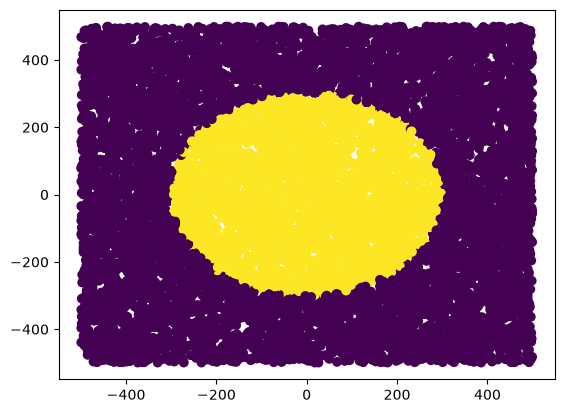

In [3]:
f = open('files/res_oval.dat')
d = []
for s in f:
    d.append([float(x) for x in s.split()]) 
d = np.array(d)
# plt.subplot(1, 2, 1)
plt.scatter(d[:, 0], d[:, 1], c=d[:, 2])

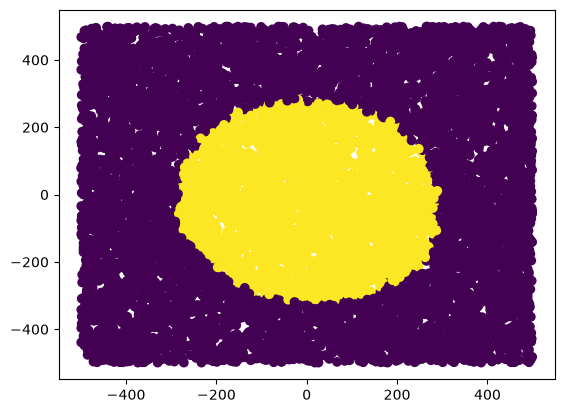

In [4]:
clf = MLPClassifier(hidden_layer_sizes=(40, 40))
clf.fit(d[:,:2], d[:,2])
yp = clf.predict(d[:,:2])

pp.scatter(d[:,0], d[:,1], c=yp)

In [5]:
print('acc@train', clf.score(d[:,:2],d[:,2]))

acc@train 0.9711


## 4. Задание: перебор размеров скрытых слоёв

Нужно подобрать размеры нейронных слоёв так, чтобы `score` был максимален, и прислать в чат картинку с разделяющими областями вместе с найденными размерами.

- Перебирать с разумным шагом, не через единицу — так слишком долго. Ориентиры: минимум 4 нейрона, максимум порядка 50 (выше не позволяют ни теорема Колмогорова–Арнольда, ни ограничение по числу параметров на 10 тысяч объектов).
- Схема: обучить, посчитать `score`, запомнить лучший классификатор (пригодится `copy.deepcopy`) и выбрать размеры, при которых точность лучшая.
- Результаты у всех будут разные: у полносвязной сети есть **симметрия** — нейроны одного слоя можно переставить местами, если так же переставить соответствующие веса следующего слоя, и ответ сети не изменится ни в одной точке. Значит, один и тот же результат дают разные наборы коэффициентов, и «свои» веса — не единственно верные.
- Присылать можно несколько решений, но проверяется последнее.
- Для сравнения: сеть `(40, 40)` из ячейки выше — это $120 + 1640 + 82 = 1842$ параметра, что заметно меньше 10 тысяч объектов.


## 5. Градиентный спуск: одна переменная

Обучение сети — это поиск минимума **функции потерь**. Минимум ищут итеративно: коэффициенты кидают случайно и шагами спускаются туда, где функция меньше.

- **Направление шага** задаёт производная. Если $f'(v) > 0$, функция растёт, и идти надо в противоположную сторону; если $f'(v) < 0$ — в сторону роста $v$. Поэтому производную берут с обратным знаком.
- **Длина шага** — скорость обучения $\alpha$, обычно от $10^{-2}$ до $10^{-6}$.

Отсюда правило обновления — **метод градиентного спуска**:

$$v_{k+1} = v_k - \alpha \cdot f'(v_k)$$

Если шагать «на всю производную», легко проскочить минимум и выпасть из него — именно поэтому шаг умножается на $\alpha$.

Разбираем функцию $f(x) = (x-5)^2$: она неотрицательна, свой минимум принимает при $x = 5$, а производная равна

$$f'(x) = 2(x-5), \qquad \min f = 0 \text{ при } x = 5$$

В коде: старт `w = 10`, `A = 1e-2` — это $\alpha$, максимум 1000 шагов, остановка при $|w - 5| < 10^{-4}$. Когда производная обратится в ноль, шаги прекратятся сами: в минимуме сдвигаться некуда, а `break` выходит из цикла, не дожидаясь лимита. Лимит в 1000 итераций страхует от зацикливания, если спуск не сойдётся.

При $\alpha = 10^{-2}$ получается 535 шагов. Увеличим скорость — получилось 48 шагов; значит, при слишком маленькой $\alpha$ долго ждёшь, при слишком большой спуск за 1000 шагов до минимума не доходит. Подбор удачного $\alpha$ разберём позже.


5.000099116640969 535


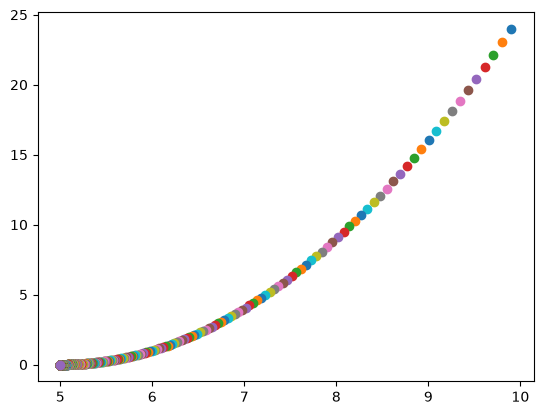

In [6]:

def f(x):
    return (x-5)**2

def dF(x):
    return 2*(x-5)

w=10
A=10**(-2)

for step in range(1000):
  dw=dF(w)
  w-=dw*A
  if abs(w-5)<1e-4:
    break
  plt.scatter(w,f(w))
print (w,step)

## 6. Градиентный спуск: две переменные

Теперь $F(x, y) = (x-5)^2 + (y-7)^2$, минимум — в точке $(5, 7)$: функция неотрицательна, а ноль достигается, когда $x = 5$ и $y = 7$. Для функции нескольких переменных берут **частные производные**: при дифференцировании по $x$ величина $y$ считается константой и наоборот.

$$\frac{\partial F}{\partial x} = 2(x-5), \qquad \frac{\partial F}{\partial y} = 2(y-7)$$

Вектор, составленный из частных производных, называется **градиентом**:

$$\nabla F = \left(\frac{\partial F}{\partial x},\ \frac{\partial F}{\partial y}\right)$$

Шаг делается сразу по обеим координатам, со знаком минус:

$$x_{k+1} = x_k - \alpha \frac{\partial F}{\partial x}, \qquad y_{k+1} = y_k - \alpha \frac{\partial F}{\partial y}$$

В коде: старт из $(10, 10)$ (чтобы было заметнее), $\alpha = 0.1$, выход из цикла — когда обе координаты сошлись к $(5, 7)$ с точностью $10^{-4}$; при $\alpha = 0.1$ это занимает порядка 48 шагов. На картинке обе компоненты рисуются разными маркерами — кружками и квадратиками.

Чтобы такой спуск сходился, функция потерь должна быть **гладкой** (производная есть везде) и без плато: производная не должна обращаться в ноль нигде, кроме точки минимума.


5.000089202980794 7.000053521788476 48


()

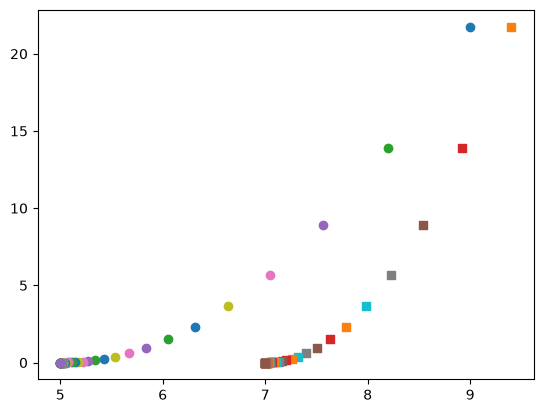

In [7]:

def F(x,y):
    return (x-5)**2+(y-7)**2

def dF(x,y):
    return 2*(x-5),2*(y-7)

w,b=10,10
A=0.1

for step in range(1000):
    dw,db=dF(w,b)
    w-=dw*A
    b-=db*A
    if abs(w-5)<1e-4 and abs(b-7)<1e-4:
        break
    plt.scatter(w,F(w,b),marker='o')
    plt.scatter(b,F(w,b),marker='s')

print (w,b,step)
plt.show
()

## 7. Как считать производные: обратное распространение ошибки

Производные функции потерь считают **методом обратного распространения ошибки** — это правило дифференцирования сложной функции (правило цепочки).

Возьмём сеть из одного нейрона с одним входом: модель $\varphi(vx + b)$, функция потерь — MSE:

$$L = \sum_t \left(y_t - \varphi(vx_t + b)\right)^2$$

Дифференцирование даёт:

$$\frac{\partial L}{\partial v} = \sum_t 2\left(y_t - \varphi(vx_t + b)\right) \cdot \varphi'(vx_t + b) \cdot x_t, \qquad \frac{\partial L}{\partial b} = \sum_t 2\left(y_t - \varphi(vx_t + b)\right) \cdot \varphi'(vx_t + b) \cdot 1$$

- сумма и множитель $2(y_t - \text{модель})$ берутся из функции потерь, со знаком суммы можно обращаться как со знаком плюс;
- множитель $\varphi'$ — производная функции активации;
- при дифференцировании по $v$ добавляется $x_t$, при дифференцировании по $b$ — единица.

### Правило цепочки

- нейроны стоят **последовательно** — производные перемножаются: $L_1 \varphi_1' \varphi_2' \varphi_3'$, то есть на своём шаге вклад даёт производная каждой функции активации;
- к нейрону ведёт **несколько путей** — вклады складываются: $L_1 \varphi_1' \varphi_2' \varphi_3' + L_1 \varphi_1' \varphi_3' \varphi_4'$.

Больше ничего вычислять не нужно, и в стандартных библиотеках это уже реализовано: достаточно вызвать готовый метод.

Отсюда требования и к функции активации: её производная должна быть гладкой и почти нигде не обращаться в ноль. Классическая сигмоида на выходе вместе с MSE не обучится — на «хвостах» она почти константа и её производная равна нулю. Функцию активации и функцию потерь подбирают друг под друга.


## 8. Тот же спуск в PyTorch: autograd

**PyTorch** — фреймворк машинного обучения, на котором сегодня пишут нейронные сети. Простые сети на нём писать неудобно, зато сложные — компактно; подробно займёмся им отдельно.

Чтобы фреймворк считал производные, тензор создают с флагом `requires_grad=True`: с этого момента PyTorch запоминает все операции над тензором, а рядом с ним появляется место под производные.

- `w = torch.tensor([[10.0], [10.0]], requires_grad=True)` — начальная точка $(10, 10)$;
- `function = (w[0]-5)**2 + (w[1]-7)**2` — функция потерь;
- `function.backward()` — считает производные по всем тензорам с `requires_grad` и записывает их в атрибут `.grad`;
- `w.data = w.data - alpha * w.grad` — сам шаг градиентного спуска; меняется именно `w.data`, потому что значение тензора, по которому считаются производные, перезаписывать напрямую нельзя;
- `w.grad.zero_()` — обнуление градиента после шага: `backward()` **накапливает** производные, и без обнуления очередной шаг считался бы по сумме старых и новых.

Условие останова в этой ячейке осталось от задачи с минимумом в $(0, 3)$: при минимуме $(5, 7)$ оно не сработает, и цикл честно выполнит все 1000 шагов. При $\alpha = 0.1$ до точки $(5, 7)$ хватает примерно 48 шагов — то же, что и в ручной реализации.


In [8]:
w=torch.tensor([[10.0],[10.0]],requires_grad=True)
alpha=0.1

for step in range(1000):
    function = (w[0]-5)**2+(w[1]-7)**2
    function.backward()
    w.data=w.data-alpha*w.grad
    w.grad.zero_()
    if abs(w.data
[0]-0)<1e-4 and abs(w.data
[1]-3)<1e-4:
        break
print (w,step)

tensor([[5.0000],
        [7.0000]], requires_grad=True) 999


## 9. На будущее: проклятие размерности

В конце занятия речь зашла о кластеризации и **проклятии размерности**: если у вас $N$ точек в $M$-мерном пространстве и $M > N$, расстояния между точками становятся примерно одинаковыми, и разбить их на кучки уже нельзя. Поэтому для $N$ точек стараются подобрать размерность пространства в пределах от $\log N$ до $\sqrt{N}$ — например, для 1000 точек это примерно от 3 до 30. Слишком большую размерность понижают (проекциями, в том числе методом главных компонент), слишком маленькую — повышают. Именно поэтому в задачах с исходным 64-мерным пространством данные приходилось переводить в пространство меньшей размерности: в исходном все точки были друг от друга на одинаковом расстоянии.


---

**Итог занятия 5.** Разобрали полносвязную нейронную сеть: нейрон — это взвешенная сумма входов со смещением, на нейрон нужно $n+1$ параметров, а главное правило — число параметров сети должно быть порядка числа объектов, иначе задача недоопределена. Обучили `MLPClassifier` на датасете `res_oval.dat` и увидели, что accuracy на обучающей выборке ничего не доказывает; получили задание перебрать размеры скрытых слоёв. Затем реализовали градиентный спуск руками для $f(x)=(x-5)^2$ и $F(x,y)=(x-5)^2+(y-7)^2$, разобрали градиент, скорость обучения, требования к функции потерь и обратное распространение ошибки. В конце повторили спуск в PyTorch через `requires_grad`, `backward()` и обнуление `.grad`.
